# AJR (2001) extension: does the effect of institutions hold when income is measured in other years?

This notebook produces every number in Section 5.1 of the report, from the source files to Table 2.

**Extension.** AJR measure income in a single year (1995). We keep their model, instrument and institutions measure fixed and only change the year in which income is measured: 1970–2025. Post-crisis years (1975, 1980, 2000, 2009) test whether major crises break the relationship. Two robustness checks change the sample: seven Middle Eastern countries are added, and an oil-rich dummy is controlled for.

**Methods (course slides, Topic 1d).**
- 2SLS of log GDP per capita on institutions (`avexpr`), instrumented by log settler mortality (`logem4`), as in AJR Table 4.
- Classic (homoskedastic) variance: OLS V̂ = s²(X'X)⁻¹ and its 2SLS analogue s²(X̂'X̂)⁻¹ with X̂ the first-stage fitted values; s² = e'e / (N − K).
- Two-sided t-tests, t = (β̂ − value) / se, compared with the critical value t_{N−K}(0.975) ≈ 2.00. First-stage F = t² (one restriction).
- Change of the effect between two years: one regression of income growth (y_t − y_s) on institutions. Because the sample and the first stage are the same in both years, its coefficient equals β_t − β_s and its standard error already includes the covariance of the two estimates.

**Inputs:** `data/source/` (see `data/source/README.md`). **Outputs:** `results/table2.csv`, `results/table2.tex`, `results/change_tests.csv`, `figures/section5/beta_by_year.png`.

In [1]:
import io, json, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=RuntimeWarning)   # spurious macOS/numpy matmul warnings

ROOT = Path.cwd()
SRC = ROOT / "data" / "source"
OUT_DIR, FIG_DIR = ROOT / "results", ROOT / "figures" / "section5"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
KEY, ALPHA = "shortnam", 0.05

TABLE_YEARS = [1970, 1975, 1980, 1995, 2000, 2009, 2025]
POST_CRISIS = {1975: "after oil shock I", 1980: "after oil shock II", 2000: "after Asian/Russian crises",
               2009: "global financial crisis"}
CHANGES = [("Divergence", 1970, 1995), ("After AJR", 1995, 2025),
           ("Oil shock I", 1973, 1975), ("Oil shock II + debt crisis", 1979, 1983),
           ("Asian and Russian crises", 1997, 1999), ("Global financial crisis", 2007, 2009)]
ALL_YEARS = sorted(set(TABLE_YEARS) | {a for _, a, _ in CHANGES} | {b for _, _, b in CHANGES})

AJR = {"beta": 0.94, "se": 0.16, "fs": -0.61, "fs_se": 0.13, "ols": 0.52, "ols_se": 0.06, "N": 64}  # AJR Table 4, col. 1
ADDED = ["SAU", "ARE", "SYR", "IRQ", "QAT", "YEM", "OMN"]   # Middle Eastern countries with avexpr in the AJR data
OIL_EXTRA = ["USA", "ISR"]                                  # coded oil-rich by hand

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID_C, AXIS, BAND = "#e1e0d9", "#c3c2b7", "#e6e5df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID_C, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

## 1. AJR data

The three replication tables that contain the variables we need are read directly from the zip files:
- Table 2: `avexpr`, `logpgp95`, `baseco` (163 countries)
- Table 4: `logem4`
- Table 1: `extmort4` (settler mortality, also for countries outside the base sample; used to impute mortality below). Table 1 has empty and duplicated country codes; empty codes are dropped and the first non-missing value is kept.

In [2]:
DTA = {}
for k in [1, 2, 4]:
    with zipfile.ZipFile(SRC / "ajr" / f"maketable{k}.zip") as z:
        name = next(n for n in z.namelist() if n.lower().endswith(".dta"))
        with pd.io.stata.StataReader(io.BytesIO(z.read(name))) as reader:
            DTA[k] = reader.read()

t1 = DTA[1][DTA[1][KEY].str.strip() != ""].groupby(KEY, as_index=False).first()
ajr = (DTA[2][[KEY, "baseco", "avexpr", "logpgp95"]]
       .merge(DTA[4][[KEY, "logem4"]], on=KEY, how="outer", validate="one_to_one")
       .merge(t1[[KEY, "extmort4"]], on=KEY, how="left", validate="one_to_one"))
ajr["iso3"] = ajr[KEY].replace({"ZAR": "COD"})   # AJR code -> ISO3
assert len(ajr) == 163 and int((ajr["baseco"] == 1).sum()) == 64
print(f"AJR data: {len(ajr)} countries, base sample {int((ajr['baseco'] == 1).sum())}")

AJR data: 163 countries, base sample 64


## 2. Income series

- **Main series: Maddison Project 2023** (GDP per capita, 2011 international $). Maddison ends in 2022. The 2025 value is the 2022 value times the 2022–2025 growth of real GDP per capita from the World Bank (constant 2015 $); where the World Bank has no 2025 value, IMF WEO real GDP growth divided by population growth is used.
- **Robustness series: World Bank** GDP per capita (constant 2015 $), used directly.

In [3]:
def read_wb(fname):
    _, rows = json.loads((SRC / fname).read_text())
    df = pd.DataFrame([{"iso3": r["countryiso3code"], "year": int(r["date"]), "value": r["value"]} for r in rows])
    df = df[df["iso3"].str.len() == 3].dropna()           # regional aggregates have no ISO3 code
    return df.pivot(index="iso3", columns="year", values="value")

wdi_gdp = read_wb("wdi_NY.GDP.PCAP.KD.json")
wdi_oil = read_wb("wdi_NY.GDP.PETR.RT.ZS.json")
imf = {ind: json.loads((SRC / f"imf_{ind}.json").read_text())["values"][ind] for ind in ["NGDP_RPCH", "LP"]}
mpd = pd.read_stata(SRC / "maddison2023_web.dta", columns=["countrycode", "year", "gdppc"])
mpd = mpd.assign(year=mpd["year"].astype(int)).pivot_table(index="countrycode", columns="year", values="gdppc")

def growth_factor(iso, y0, y1):
    """Real GDP per capita in y1 relative to y0: World Bank first, otherwise IMF (real growth / population growth)."""
    if iso in wdi_gdp.index and pd.notna(wdi_gdp.loc[iso].get(y0)) and pd.notna(wdi_gdp.loc[iso].get(y1)):
        return wdi_gdp.loc[iso, y1] / wdi_gdp.loc[iso, y0], "World Bank"
    g, p = imf["NGDP_RPCH"].get(iso, {}), imf["LP"].get(iso, {})
    yrs = [str(y) for y in range(y0 + 1, y1 + 1)]
    if all(y in g for y in yrs) and str(y0) in p and str(y1) in p:
        return np.prod([1 + g[y] / 100 for y in yrs]) / (p[str(y1)] / p[str(y0)]), "IMF"
    return np.nan, "none"

ext25 = {iso: growth_factor(iso, 2022, 2025) for iso in mpd.index}
mpd[2025] = mpd[2022] * pd.Series({iso: f for iso, (f, _) in ext25.items()})
Y_MPD, Y_WDI = np.log(mpd), np.log(wdi_gdp)
print("Source of the 2022–2025 extension (Maddison countries):",
      pd.Series({iso: s for iso, (_, s) in ext25.items()}).value_counts().to_dict())

Source of the 2022–2025 extension (Maddison countries): {'World Bank': 158, 'none': 6, 'IMF': 5}


## 3. Samples

- **A. Base sample:** AJR's 64 former colonies.
- **B. Base + Middle East:** seven Middle Eastern countries that have an institutions measure in the AJR data but no settler mortality. Each is assigned the mortality of the AJR country with the nearest capital (great-circle distance), the same idea AJR use for countries without own data. (Argentina and Venezuela are already in the base sample; Lebanon has no `avexpr`.)
- **C. Base + Middle East + oil dummy:** sample B with an oil-rich dummy as an exogenous control in both stages. Oil-rich = mean 1970–1995 oil rents ≥ 10% of GDP (World Bank), plus the USA and Israel.

All Maddison results use a **balanced sample**: countries with income in every year used in this notebook, so that differences across years are not driven by changes in the country set.

In [4]:
_, wb_rows = json.loads((SRC / "wb_countries.json").read_text())
cap = pd.DataFrame([{"iso3": r["id"], "lat": float(r["latitude"] or "nan"), "lon": float(r["longitude"] or "nan")}
                    for r in wb_rows]).set_index("iso3")

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

donors = ajr.loc[ajr["extmort4"].notna(), [KEY, "iso3", "extmort4"]].join(cap, on="iso3")
imputation = []
for c in ADDED:
    dist = haversine(cap.loc[c, "lat"], cap.loc[c, "lon"], donors["lat"], donors["lon"])
    j = dist.idxmin()
    imputation.append({"country": c, "donor": donors.loc[j, KEY], "distance_km": round(dist[j]),
                       "settler mortality": donors.loc[j, "extmort4"]})
imputation = pd.DataFrame(imputation).set_index("country")

oil_mean = wdi_oil.loc[:, 1970:1995].mean(axis=1)
ext = ajr[(ajr["baseco"] == 1) | ajr[KEY].isin(ADDED)].copy()
ext["added"] = ext[KEY].isin(ADDED).astype(int)
ext["logem4_x"] = np.where(ext["added"] == 1, np.log(ext[KEY].map(imputation["settler mortality"])), ext["logem4"])
ext["oil"] = ((ext["iso3"].map(oil_mean) >= 10) | ext[KEY].isin(OIL_EXTRA)).astype(int)
for y in ALL_YEARS:
    ext[f"y{y}"] = ext["iso3"].map(Y_MPD[y])
    ext[f"w{y}"] = ext["iso3"].map(Y_WDI[y])
base = ext[ext["added"] == 0]

def balanced(d, prefix="y"):
    return d.dropna(subset=[f"{prefix}{y}" for y in ALL_YEARS])

SAMPLES = {"A. Base sample": (base, ()), "B. Base + Middle East": (ext, ()),
           "C. Base + Middle East + oil dummy": (ext, ("oil",))}
display(imputation)
print("Oil-rich countries:", ", ".join(sorted(ext.loc[ext["oil"] == 1, KEY])))
for name, (d, _) in SAMPLES.items():
    kept = balanced(d)
    print(f"{name}: {len(kept)} of {len(d)} countries in the balanced Maddison sample; "
          f"dropped: {', '.join(sorted(set(d[KEY]) - set(kept[KEY]))) or 'none'}")

,donor,distance_km,settler mortality
country,,,
SAU,DJI,1503,26.000000
ARE,AFG,1813,93.699997
SYR,EGY,611,67.800003
IRQ,EGY,1293,67.800003
QAT,DJI,1760,26.000000
YEM,DJI,435,26.000000
OMN,AFG,1589,93.699997


Oil-rich countries: AGO, ARE, COG, DZA, EGY, GAB, IRQ, NGA, OMN, QAT, SAU, TTO, USA, VEN, YEM
A. Base sample: 62 of 64 countries in the balanced Maddison sample; dropped: BHS, GUY
B. Base + Middle East: 68 of 71 countries in the balanced Maddison sample; dropped: BHS, GUY, SYR
C. Base + Middle East + oil dummy: 68 of 71 countries in the balanced Maddison sample; dropped: BHS, GUY, SYR


The Bahamas (BHS) and Guyana (GUY) are not covered by Maddison; Syria (SYR) has no 2025 value in any source.

## 4. Estimation (matrix formulas from the slides)

In [5]:
def ols(y, X):
    """OLS with the classic variance V = s²(X'X)⁻¹, s² = e'e / (N − K)."""
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    N, K = X.shape
    return {"b": b, "se": np.sqrt(np.diag(e @ e / (N - K) * XtX_inv)), "N": N, "df": N - K}

def tsls(y, X, Z):
    """2SLS: b = (X̂'X̂)⁻¹X̂'y with X̂ = first-stage fitted values; V = s²(X̂'X̂)⁻¹, s² = e'e / (N − K), e = y − Xb."""
    Xh = Z @ np.linalg.lstsq(Z, X, rcond=None)[0]
    A = np.linalg.inv(Xh.T @ Xh)
    b = A @ Xh.T @ y
    e = y - X @ b                      # residuals use the actual X, not the fitted values
    N, K = X.shape
    return {"b": b, "se": np.sqrt(np.diag(e @ e / (N - K) * A)), "N": N, "df": N - K}

def t_test(est, se, df, value=0.0):
    """Two-sided t-test of H0: coefficient = value."""
    t = (est - value) / se
    crit = stats.t.ppf(1 - ALPHA / 2, df)
    return {"t": t, "p": 2 * stats.t.sf(abs(t), df), "crit": crit, "reject": abs(t) > crit}

def estimate(d, ycol, controls=()):
    """2SLS of ycol on avexpr (instrument: settler mortality), its first stage and OLS, with the same controls."""
    d = d.dropna(subset=[ycol, "avexpr", "logem4_x", *controls])
    W = [np.ones(len(d))] + [d[c].to_numpy(float) for c in controls]
    y = d[ycol].to_numpy(float)
    X = np.column_stack(W + [d["avexpr"].to_numpy(float)])
    Z = np.column_stack(W + [d["logem4_x"].to_numpy(float)])
    iv, fs, ls = tsls(y, X, Z), ols(X[:, -1], Z), ols(y, X)
    out = {"N": iv["N"], "df": iv["df"], "beta": iv["b"][-1], "se": iv["se"][-1],
           "fs": fs["b"][-1], "fs_se": fs["se"][-1], "F": (fs["b"][-1] / fs["se"][-1]) ** 2,
           "ols": ls["b"][-1], "ols_se": ls["se"][-1]}
    for j, c in enumerate(controls, start=1):
        out[f"{c}_coef"], out[f"{c}_se"] = iv["b"][j], iv["se"][j]
    return out

# Replication check: AJR Table 4, column 1
rep = estimate(base, "logpgp95")
print(f"Replication with AJR data: 2SLS {rep['beta']:.2f} ({rep['se']:.2f}), first stage {rep['fs']:.2f} ({rep['fs_se']:.2f}), "
      f"OLS {rep['ols']:.2f} ({rep['ols_se']:.2f}), N = {rep['N']}")
assert all(abs(rep[k] - AJR[k]) < 0.006 for k in ["beta", "se", "fs", "fs_se", "ols", "ols_se"]) and rep["N"] == AJR["N"]

Replication with AJR data: 2SLS 0.94 (0.16), first stage -0.61 (0.13), OLS 0.52 (0.06), N = 64


## 5. Table 2: the effect of institutions by income year

Each column is a separate 2SLS regression; only the year of the dependent variable changes. The first column uses AJR's own 1995 data. For every coefficient two t-tests are reported:
- **H0: β = 0** (stars),
- **H0: β = 0.94** (AJR's estimate).

In [6]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def column(d, ycol, controls):
    r = estimate(d, ycol, controls)
    r["test0"] = t_test(r["beta"], r["se"], r["df"])
    r["test094"] = t_test(r["beta"], r["se"], r["df"], value=AJR["beta"])
    if controls:
        r["test_oil"] = t_test(r["oil_coef"], r["oil_se"], r["df"])
    return r

COLS = [("AJR data, 1995", None)] + [(f"{y}{' †' if y in POST_CRISIS else ''}", y) for y in TABLE_YEARS]
results = {}
for name, (d, ctr) in SAMPLES.items():
    dd = balanced(d)
    for col, year in COLS:
        results[(name, col)] = column(d, "logpgp95", ctr) if year is None else column(dd, f"y{year}", ctr)

rows = []
for name, (d, ctr) in SAMPLES.items():
    for label in ["2SLS: avexpr", "t-test H0: β = 0.94", "Oil dummy", "First stage: log mortality",
                  "First-stage F", "OLS: avexpr", "N"]:
        if label == "Oil dummy" and not ctr:
            continue
        row = {"panel": name, "": label}
        for col, _ in COLS:
            r = results[(name, col)]
            row[col] = {
                "2SLS: avexpr": f"{r['beta']:.2f}{stars(r['test0']['p'])} ({r['se']:.2f})",
                "t-test H0: β = 0.94": f"{r['test094']['t']:.2f} (p = {r['test094']['p']:.2f})",
                "Oil dummy": f"{r.get('oil_coef', np.nan):.2f}{stars(r['test_oil']['p'])} ({r.get('oil_se', np.nan):.2f})" if ctr else "",
                "First stage: log mortality": f"{r['fs']:.2f} ({r['fs_se']:.2f})",
                "First-stage F": f"{r['F']:.1f}",
                "OLS: avexpr": f"{r['ols']:.2f} ({r['ols_se']:.2f})",
                "N": f"{r['N']}",
            }[label]
        rows.append(row)
table2 = pd.DataFrame(rows).set_index(["panel", ""])
table2.to_csv(OUT_DIR / "table2.csv")
display(table2)
print("Standard errors in parentheses. *** p < 0.01, ** p < 0.05, * p < 0.10 (H0: β = 0). † post-crisis year.")

AJR data, 1995              1970            1975 †            1980 †             1995           2000 †           2009 †             2025
panel                                                                                                                                                                                                   
A. Base sample                    2SLS: avexpr                  0.94*** (0.16)    0.67*** (0.13)    0.73*** (0.14)    0.82*** (0.15)   1.01*** (0.16)   1.04*** (0.17)   1.01*** (0.17)   1.01*** (0.16)
                                  t-test H0: β = 0.94          0.03 (p = 0.98)  -2.09 (p = 0.04)  -1.49 (p = 0.14)  -0.84 (p = 0.40)  0.43 (p = 0.67)  0.61 (p = 0.55)  0.42 (p = 0.68)  0.43 (p = 0.67)
                                  First stage: log mortality      -0.61 (0.13)      -0.62 (0.13)      -0.62 (0.13)      -0.62 (0.13)     -0.62 (0.13)     -0.62 (0.13)     -0.62 (0.13)     -0.62 (0.13)
                                  First-stage F                           22.9              23.5              23.5              23.5             23.5             23.5             23.5             23.5
                                  OLS: avexpr                      0.52 (0.06)       0.37 (0.06)       0.41 (0.06)       0.45 (0.06)      0.56 (0.06)      0.57 (0.07)      0.54 (0.07)      0.57 (0.06)
                                  N                                         64                62                62                62               62               62               62               62
B. Base + Middle East             2SLS: avexpr                  0.94*** (0.15)    0.74*** (0.17)    0.82*** (0.18)    0.90*** (0.19)   1.06*** (0.19)   1.11*** (0.21)   1.10*** (0.22)   1.07*** (0.21)
                                  t-test H0: β = 0.94         -0.03 (p = 0.98)  -1.17 (p = 0.24)  -0.66 (p = 0.51)  -0.20 (p = 0.84)  0.62 (p = 0.54)  0.83 (p = 0.41)  0.72 (p = 0.47)  0.61 (p = 0.54)
                                  First stage: log mortality      -0.60 (0.12)      -0.60 (0.13)      -0.60 (0.13)      -0.60 (0.13)     -0.60 (0.13)     -0.60 (0.13)     -0.60 (0.13)     -0.60 (0.13)
                                  First-stage F                           25.2              19.6              19.6              19.6             19.6             19.6             19.6             19.6
                                  OLS: avexpr                      0.54 (0.06)       0.34 (0.06)       0.37 (0.07)       0.39 (0.07)      0.52 (0.06)      0.52 (0.07)      0.49 (0.07)      0.51 (0.07)
                                  N                                         70                68                68                68               68               68               68               68
C. Base + Middle East + oil dummy 2SLS: avexpr                  0.93*** (0.15)    0.72*** (0.16)    0.80*** (0.17)    0.88*** (0.18)   1.04*** (0.19)   1.09*** (0.20)   1.07*** (0.21)   1.05*** (0.20)
                                  t-test H0: β = 0.94         -0.04 (p = 0.97)  -1.37 (p = 0.18)  -0.82 (p = 0.42)  -0.32 (p = 0.75)  0.56 (p = 0.58)  0.76 (p = 0.45)  0.65 (p = 0.52)  0.55 (p = 0.59)
                                  Oil dummy                        0.09 (0.29)    0.75*** (0.28)     0.80** (0.30)     0.80** (0.33)     0.58* (0.33)    0.77** (0.36)   1.01*** (0.37)     0.66* (0.36)
                                  First stage: log mortality      -0.59 (0.12)      -0.60 (0.14)      -0.60 (0.14)      -0.60 (0.14)     -0.60 (0.14)     -0.60 (0.14)     -0.60 (0.14)     -0.60 (0.14)
                                  First-stage F                           25.0              19.2              19.2              19.2             19.2             19.2             19.2             19.2
                                  OLS: avexpr                      0.53 (0.06)       0.33 (0.06)       0.36 (0.06)       0.38 (0.06)      0.51 (0.06)      0.52 (0.06)      0.48 (0.07)      0.50 (0.07)
                                  N         

Standard errors in parentheses. *** p < 0.01, ** p < 0.05, * p < 0.10 (H0: β = 0). † post-crisis year.


**Test decisions at the 5% level** (critical value ≈ ±2.00):

In [7]:
dec = pd.DataFrame({(name, col): {"H0: β = 0": "reject" if r["test0"]["reject"] else "fail to reject",
                                  "H0: β = 0.94": "reject" if r["test094"]["reject"] else "fail to reject"}
                    for (name, col), r in results.items()}).T
dec.index.names = ["panel", "column"]
dec.unstack("column")[[f"{h}" for h in ["H0: β = 0", "H0: β = 0.94"]]].reindex(columns=[c for c, _ in COLS], level=1)

H0: β = 0                                                            H0: β = 0.94                                                                                                  \
column                            AJR data, 1995    1970  1975 †  1980 †    1995  2000 †  2009 †    2025  AJR data, 1995            1970          1975 †          1980 †            1995          2000 †          2009 †   
panel                                                                                                                                                                                                                      
A. Base sample                            reject  reject  reject  reject  reject  reject  reject  reject  fail to reject          reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject   
B. Base + Middle East                     reject  reject  reject  reject  reject  reject  reject  reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject   
C. Base + Middle East + oil dummy         reject  reject  reject  reject  reject  reject  reject  reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject  fail to reject   

                                                   
column                                       2025  
panel                                              
A. Base sample                     fail to reject  
B. Base + Middle East              fail to reject  
C. Base + Middle East + oil dummy  fail to reject

## 6. Did the effect change between two years?

For years s < t: regress income growth y_t − y_s on institutions (2SLS, same instrument and controls). The coefficient is Δβ = β_t − β_s; H0: Δβ = 0 is a single t-test. As a check, the reduced form version (OLS of growth on settler mortality) is also reported: because the first stage is the same in both years, β_t = β_s exactly when the two reduced-form coefficients are equal.

- **Main extension:** 1970 → 1995 and 1995 → 2025.
- **Crisis windows:** the year before each crisis to the year after it.

In [8]:
change_rows = []
for label, s, t in CHANGES:
    for name, (d, ctr) in SAMPLES.items():
        dd = balanced(d).assign(growth=lambda x: x[f"y{t}"] - x[f"y{s}"])
        r = estimate(dd, "growth", ctr)
        tt = t_test(r["beta"], r["se"], r["df"])
        W = [np.ones(len(dd))] + [dd[c].to_numpy(float) for c in ctr]
        rf = ols(dd["growth"].to_numpy(float), np.column_stack(W + [dd["logem4_x"].to_numpy(float)]))
        rf_t = t_test(rf["b"][-1], rf["se"][-1], rf["df"])
        change_rows.append({"change": f"{label}: {s}–{t}", "panel": name, "N": r["N"],
                            "Δβ": r["beta"], "se": r["se"], "t": tt["t"], "p": tt["p"],
                            "decision (5%)": "reject" if tt["reject"] else "fail to reject",
                            "reduced form: t": rf_t["t"], "reduced form: p": rf_t["p"]})
changes = pd.DataFrame(change_rows)
changes.to_csv(OUT_DIR / "change_tests.csv", index=False)
changes.set_index(["change", "panel"]).round(3)

N     Δβ     se      t      p   decision (5%)  reduced form: t  reduced form: p
change                                panel                                                                                                              
Divergence: 1970–1995                 A. Base sample                     62  0.344  0.079  4.329  0.000          reject           -4.975            0.000
                                      B. Base + Middle East              68  0.317  0.083  3.821  0.000          reject           -3.971            0.000
                                      C. Base + Middle East + oil dummy  68  0.321  0.083  3.852  0.000          reject           -4.022            0.000
After AJR: 1995–2025                  A. Base sample                     62 -0.002  0.068 -0.024  0.981  fail to reject            0.024            0.981
                                      B. Base + Middle East              68  0.008  0.081  0.094  0.926  fail to reject           -0.094            0.926
                                      C. Base + Middle East + oil dummy  68  0.006  0.082  0.069  0.945  fail to reject           -0.069            0.945
Oil shock I: 1973–1975                A. Base sample                     62  0.024  0.017  1.398  0.167  fail to reject           -1.431            0.158
                                      B. Base + Middle East              68  0.022  0.019  1.177  0.243  fail to reject           -1.222            0.226
                                      C. Base + Middle East + oil dummy  68  0.022  0.019  1.165  0.248  fail to reject           -1.209            0.231
Oil shock II + debt crisis: 1979–1983 A. Base sample                     62  0.064  0.025  2.560  0.013          reject           -2.893            0.005
                                      B. Base + Middle East              68  0.043  0.028  1.507  0.137  fail to reject           -1.504            0.137
                                      C. Base + Middle East + oil dummy  68  0.044  0.028  1.576  0.120  fail to reject           -1.576            0.120
Asian and Russian crises: 1997–1999   A. Base sample                     62 -0.001  0.010 -0.120  0.905  fail to reject            0.120            0.905
                                      B. Base + Middle East              68  0.006  0.013  0.492  0.624  fail to reject           -0.506            0.614
                                      C. Base + Middle East + oil dummy  68  0.005  0.012  0.388  0.699  fail to reject           -0.397            0.692
Global financial crisis: 2007–2009    A. Base sample                     62 -0.022  0.009 -2.618  0.011          reject            2.687            0.009
                                      B. Base + Middle East              68 -0.017  0.010 -1.779  0.080  fail to reject            1.708            0.092
                                      C. Base + Middle East + oil dummy  68 -0.019  0.009 -1.962  0.054  fail to reject            1.878            0.065

## 7. Robustness: World Bank income series

The same base-sample regressions with World Bank GDP per capita (constant 2015 $) instead of Maddison. Balanced World Bank sample.

In [9]:
wb = balanced(base, prefix="w")
print(f"Balanced World Bank sample: {len(wb)} countries; dropped: {', '.join(sorted(set(base[KEY]) - set(wb[KEY])))}")
wb_rows = {}
for y in TABLE_YEARS:
    r = estimate(wb, f"w{y}")
    wb_rows[f"{y}{' †' if y in POST_CRISIS else ''}"] = f"{r['beta']:.2f}{stars(t_test(r['beta'], r['se'], r['df'])['p'])} ({r['se']:.2f})"
display(pd.DataFrame(wb_rows, index=["2SLS: avexpr (World Bank income)"]))
wb_changes = []
for label, s, t in CHANGES[:2]:
    r = estimate(wb.assign(growth=wb[f"w{t}"] - wb[f"w{s}"]), "growth")
    tt = t_test(r["beta"], r["se"], r["df"])
    wb_changes.append({"change": f"{label}: {s}–{t}", "Δβ": r["beta"], "se": r["se"], "t": tt["t"], "p": tt["p"],
                       "decision (5%)": "reject" if tt["reject"] else "fail to reject"})
pd.DataFrame(wb_changes).set_index("change").round(3)

Balanced World Bank sample: 60 countries; dropped: AGO, BHS, UGA, VNM


,1970,1975 †,1980 †,1995,2000 †,2009 †,2025
2SLS: avexpr (World Bank income),0.80*** (0.18),0.83*** (0.19),0.90*** (0.19),1.13*** (0.21),1.18*** (0.21),1.22*** (0.22),1.27*** (0.23)


,Δβ,se,t,p,decision (5%)
change,,,,,
Divergence: 1970–1995,0.335,0.092,3.641,0.001,reject
After AJR: 1995–2025,0.134,0.089,1.501,0.139,fail to reject


## 8. Figure

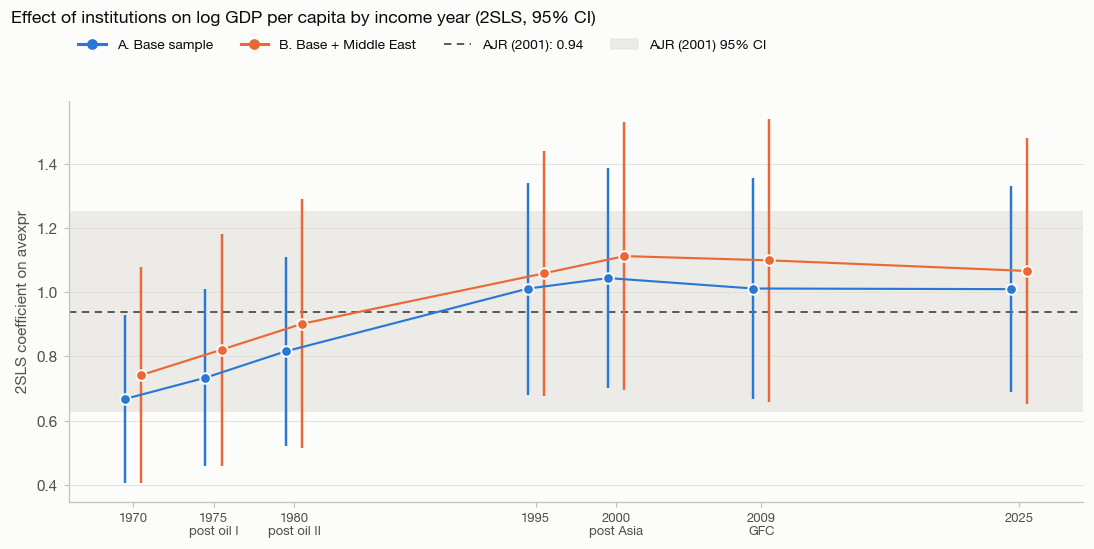

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axhspan(AJR["beta"] - 1.96 * AJR["se"], AJR["beta"] + 1.96 * AJR["se"], color=BAND, alpha=0.7, linewidth=0, zorder=0)
ax.axhline(AJR["beta"], color=INK2, linestyle=(0, (4, 3)), linewidth=1.2, zorder=1)
for (name, color, dx) in [("A. Base sample", BLUE, -0.5), ("B. Base + Middle East", ORANGE, 0.5)]:
    xs = np.array(TABLE_YEARS) + dx
    rs = [results[(name, f"{y}{' †' if y in POST_CRISIS else ''}")] for y in TABLE_YEARS]
    b = np.array([r["beta"] for r in rs])
    half = np.array([r["test0"]["crit"] * r["se"] for r in rs])
    ax.vlines(xs, b - half, b + half, color=color, linewidth=1.6, zorder=2)
    ax.plot(xs, b, color=color, linewidth=1.4, zorder=3)
    ax.scatter(xs, b, s=48, color=color, edgecolor=SURFACE, linewidth=1.2, zorder=4)
TICK_NOTE = {1975: "post oil I", 1980: "post oil II", 2000: "post Asia", 2009: "GFC"}
ax.set_xticks(TABLE_YEARS, labels=[f"{y}\n{TICK_NOTE[y]}" if y in TICK_NOTE else str(y) for y in TABLE_YEARS], fontsize=8.5)
ax.set_xlim(1966, 2029)
ax.set_ylabel("2SLS coefficient on avexpr")
ax.grid(axis="x", visible=False)
handles = [Line2D([], [], color=BLUE, marker="o", label="A. Base sample"),
           Line2D([], [], color=ORANGE, marker="o", label="B. Base + Middle East"),
           Line2D([], [], color=INK2, linestyle=(0, (4, 3)), linewidth=1.2, label="AJR (2001): 0.94"),
           Patch(color=BAND, alpha=0.7, label="AJR (2001) 95% CI")]
fig.legend(handles=handles, loc="upper left", ncol=4, fontsize=9, bbox_to_anchor=(0.06, 1.0))
fig.suptitle("Effect of institutions on log GDP per capita by income year (2SLS, 95% CI)",
             x=0.01, y=1.03, ha="left", fontsize=11.5, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG_DIR / "beta_by_year.png")
plt.show()

## 9. LaTeX export of Table 2

In [11]:
import re
def tex(s):
    if not isinstance(s, str):
        return s
    s = re.sub(r"\*{1,3}", lambda m: "$^{" + m.group(0) + "}$", s)
    return s.replace("†", r"$^\dagger$").replace("β", r"$\beta$")

col_heads = ["AJR data"] + [str(y) + (r"$^\dagger$" if y in POST_CRISIS else "") for y in TABLE_YEARS]
lines = [r"\begin{tabular}{l" + "c" * len(COLS) + "}", r"\toprule",
         " & (1) & " + " & ".join(f"({i})" for i in range(2, len(COLS) + 1)) + r" \\",
         "Income year & 1995 & " + " & ".join(col_heads[1:]) + r" \\", r"\midrule"]
for name in SAMPLES:
    lines.append(r"\multicolumn{" + str(len(COLS) + 1) + r"}{l}{\textit{Panel " + name + r"}} \\")
    sub = table2.loc[name]
    for label, row in sub.iterrows():
        lines.append(tex(label) + " & " + " & ".join(tex(v) for v in row.values) + r" \\")
    lines.append(r"\midrule")
lines[-1] = r"\bottomrule"
lines.append(r"\end{tabular}")
(OUT_DIR / "table2.tex").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

\begin{tabular}{lcccccccc}
\toprule
 & (1) & (2) & (3) & (4) & (5) & (6) & (7) & (8) \\
Income year & 1995 & 1970 & 1975$^\dagger$ & 1980$^\dagger$ & 1995 & 2000$^\dagger$ & 2009$^\dagger$ & 2025 \\
\midrule
\multicolumn{9}{l}{\textit{Panel A. Base sample}} \\
2SLS: avexpr & 0.94$^{***}$ (0.16) & 0.67$^{***}$ (0.13) & 0.73$^{***}$ (0.14) & 0.82$^{***}$ (0.15) & 1.01$^{***}$ (0.16) & 1.04$^{***}$ (0.17) & 1.01$^{***}$ (0.17) & 1.01$^{***}$ (0.16) \\
t-test H0: $\beta$ = 0.94 & 0.03 (p = 0.98) & -2.09 (p = 0.04) & -1.49 (p = 0.14) & -0.84 (p = 0.40) & 0.43 (p = 0.67) & 0.61 (p = 0.55) & 0.42 (p = 0.68) & 0.43 (p = 0.67) \\
First stage: log mortality & -0.61 (0.13) & -0.62 (0.13) & -0.62 (0.13) & -0.62 (0.13) & -0.62 (0.13) & -0.62 (0.13) & -0.62 (0.13) & -0.62 (0.13) \\
First-stage F & 22.9 & 23.5 & 23.5 & 23.5 & 23.5 & 23.5 & 23.5 & 23.5 \\
OLS: avexpr & 0.52 (0.06) & 0.37 (0.06) & 0.41 (0.06) & 0.45 (0.06) & 0.56 (0.06) & 0.57 (0.07) & 0.54 (0.07) & 0.57 (0.06) \\
N & 64 & 62 & 62 & 62

## 10. Summary (generated from the results above)

In [12]:
post = [(n, c) for (n, c) in results if c.rstrip(" †").isdigit() and int(c.rstrip(" †")) in POST_CRISIS]
allyrs = [(n, c) for (n, c) in results if c != "AJR data, 1995"]
rej0 = sum(results[k]["test0"]["reject"] for k in post)
rej0_all = sum(results[k]["test0"]["reject"] for k in allyrs)
rej094 = [k for k in allyrs if results[k]["test094"]["reject"]]
A = "A. Base sample"
path = " → ".join(f"{y}: {results[(A, f'{y}' + (' †' if y in POST_CRISIS else ''))]['beta']:.2f}" for y in TABLE_YEARS)
ch = changes.set_index(["change", "panel"])
lines = [
    f"- **Base sample, β by year:** {path} (AJR: {AJR['beta']}).",
    f"- **H0: β = 0** is rejected in {rej0_all}/{len(allyrs)} sample-years (post-crisis years: {rej0}/{len(post)}).",
    f"- **H0: β = 0.94** is rejected in {len(rej094)}/{len(allyrs)} sample-years"
    + (": " + "; ".join(f"{n}, {c} (t = {results[(n, c)]['test094']['t']:.2f})" for n, c in rej094) if rej094 else "") + ".",
]
for label, s, t in CHANGES:
    r = ch.loc[(f"{label}: {s}–{t}", A)]
    lines.append(f"- **{label} ({s}–{t}), base sample:** Δβ = {r['Δβ']:+.3f} ({r['se']:.3f}), t = {r['t']:.2f}, p = {r['p']:.3f} → {r['decision (5%)']}.")
display(Markdown("\n".join(lines)))

- **Base sample, β by year:** 1970: 0.67 → 1975: 0.73 → 1980: 0.82 → 1995: 1.01 → 2000: 1.04 → 2009: 1.01 → 2025: 1.01 (AJR: 0.94).
- **H0: β = 0** is rejected in 21/21 sample-years (post-crisis years: 12/12).
- **H0: β = 0.94** is rejected in 1/21 sample-years: A. Base sample, 1970 (t = -2.09).
- **Divergence (1970–1995), base sample:** Δβ = +0.344 (0.079), t = 4.33, p = 0.000 → reject.
- **After AJR (1995–2025), base sample:** Δβ = -0.002 (0.068), t = -0.02, p = 0.981 → fail to reject.
- **Oil shock I (1973–1975), base sample:** Δβ = +0.024 (0.017), t = 1.40, p = 0.167 → fail to reject.
- **Oil shock II + debt crisis (1979–1983), base sample:** Δβ = +0.064 (0.025), t = 2.56, p = 0.013 → reject.
- **Asian and Russian crises (1997–1999), base sample:** Δβ = -0.001 (0.010), t = -0.12, p = 0.905 → fail to reject.
- **Global financial crisis (2007–2009), base sample:** Δβ = -0.022 (0.009), t = -2.62, p = 0.011 → reject.